In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Dataset path
DATA_PATH = Path("../data/raw/financial_news_events.csv")

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (3024, 12)


,Date,Headline,Source,Market_Event,Market_Index,Index_Change_Percent,Trading_Volume,Sentiment,Sector,Impact_Level,Related_Company,News_Url
0,2025-05-21,Nikkei 225 index benefits from a weaker yen,Times of India,Commodity Price Shock,DAX,3.52,166.45,NaN,Technology,High,Goldman Sachs,https://timesofindia.indiatimes.com/business/m...
1,2025-05-18,Government subsidy program gives a lift to the...,Financial Times,Central Bank Meeting,Shanghai Composite,-3.39,57.61,NaN,Retail,Low,ExxonMobil,https://timesofindia.indiatimes.com/business/m...
2,2025-06-25,New housing data release shows a slowdown in m...,The Hindu Business Line,Consumer Confidence Report,Shanghai Composite,-0.05,403.22,Neutral,Retail,Medium,Boeing,https://www.moneycontrol.com/us-markets/sp-500
3,2025-07-21,Massive stock buyback program announced by a c...,The Economist,Commodity Price Shock,NSE Nifty,-2.29,100.11,Positive,Consumer Goods,Low,Samsung Electronics,https://www.cnbc.com/2025/09/automotive-indust...
4,2025-07-23,Government spending bill is expected to stimul...,The Motley Fool,Inflation Data Release,Nasdaq Composite,-3.97,438.22,Negative,Consumer Goods,Low,JP Morgan Chase,https://www.bloomberg.com/australia/asx-200-pe...


In [2]:

# 1. Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# 2. Column names and data types
print("\n--- DATA TYPES ---")
display(df.dtypes.to_frame(name="Data Type"))

# 3. Dataset information
print("\n--- DATASET INFO ---")
df.info()

# 4. Statistical summary
print("\n--- NUMERICAL SUMMARY ---")
display(df.describe().T)

# 5. Categorical summary
print("\n--- CATEGORICAL SUMMARY ---")
display(df.describe(include="object").T)



Rows: 3024
Columns: 12

--- DATA TYPES ---


,Data Type
Date,object
Headline,object
Source,object
Market_Event,object
Market_Index,object
Index_Change_Percent,float64
Trading_Volume,float64
Sentiment,object
Sector,object
Impact_Level,object



--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3024 entries, 0 to 3023
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  3024 non-null   object 
 1   Headline              2876 non-null   object 
 2   Source                3024 non-null   object 
 3   Market_Event          3024 non-null   object 
 4   Market_Index          3024 non-null   object 
 5   Index_Change_Percent  2863 non-null   float64
 6   Trading_Volume        3024 non-null   float64
 7   Sentiment             2853 non-null   object 
 8   Sector                3024 non-null   object 
 9   Impact_Level          3024 non-null   object 
 10  Related_Company       3024 non-null   object 
 11  News_Url              2871 non-null   object 
dtypes: float64(2), object(10)
memory usage: 283.6+ KB

--- NUMERICAL SUMMARY ---


,count,mean,std,min,25%,50%,75%,max
Index_Change_Percent,2863.0,-0.021753,2.851991,-4.99,-2.4500,-0.10,2.475,5.00
Trading_Volume,3024.0,249.037917,145.497932,1.06,120.4275,244.02,377.000,499.83



--- CATEGORICAL SUMMARY ---


,count,unique,top,freq
Date,3024,195,2025-05-01,26
Headline,2876,50,Automotive industry faces headwinds from risin...,82
Source,3024,18,Barron's,197
Market_Event,3024,20,Market Rally,183
Market_Index,3024,18,Dow Jones,198
Sentiment,2853,3,Negative,974
Sector,3024,18,Transportation,184
Impact_Level,3024,3,Medium,1039
Related_Company,3024,10,Samsung Electronics,336
News_Url,2871,50,https://www.bloomberg.com/australia/asx-200-pe...,73


In [3]:

# Missing values
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing.sort_values("Missing Percentage", ascending=False))

# Exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Duplicate headlines
print("Duplicate headline rows:", df["Headline"].duplicated().sum())

# Unique headlines
print("Unique headlines:", df["Headline"].nunique())

# Unique event categories
print("Unique market events:", df["Market_Event"].nunique())


,Missing Count,Missing Percentage
Sentiment,171,5.65
Index_Change_Percent,161,5.32
News_Url,153,5.06
Headline,148,4.89
Market_Event,0,0.00
Source,0,0.00
Date,0,0.00
Market_Index,0,0.00
Trading_Volume,0,0.00
Sector,0,0.00


Exact duplicate rows: 0
Duplicate headline rows: 2973
Unique headlines: 50
Unique market events: 20


In [4]:

# Exclude missing headlines for this analysis
headline_df = df.dropna(subset=["Headline"]).copy()

# Normalize headline text for comparison
headline_df["Headline_Clean"] = (
    headline_df["Headline"]
    .str.strip()
    .str.lower()
)

# Count occurrences of each headline
headline_counts = (
    headline_df["Headline_Clean"]
    .value_counts()
)

print("Total non-missing headline records:",
      len(headline_df))

print("Unique normalized headlines:",
      headline_df["Headline_Clean"].nunique())

print("Repeated headline groups:",
      (headline_counts > 1).sum())

print("\nTop 15 repeated headlines:")
display(headline_counts.head(15).to_frame(
    name="Occurrences"
))


Total non-missing headline records: 2876
Unique normalized headlines: 50
Repeated headline groups: 50

Top 15 repeated headlines:


,Occurrences
Headline_Clean,
automotive industry faces headwinds from rising material costs,82
semiconductor shortages weigh heavily on tech sector profits,72
utilities sector remains stable during market fluctuations,70
geopolitical ceasefire prompts a broad market recovery,69
government subsidy program gives a lift to the agriculture sector,69
real estate sector shows signs of overheating as interest rates fall,68
asx 200 gains on strong export performance,68
government spending bill is expected to stimulate the economy,67
tech giant's new product launch sparks sector-wide gains,65


In [5]:

# Number of unique labels for each headline
headline_groups = headline_df.groupby(
    "Headline_Clean"
).agg(
    Occurrences=("Headline_Clean", "size"),
    Unique_Events=("Market_Event", "nunique"),
    Unique_Sentiments=("Sentiment", "nunique"),
    Unique_Companies=("Related_Company", "nunique"),
    Unique_Dates=("Date", "nunique")
)

# Headlines having conflicting event labels
conflicting_events = headline_groups[
    headline_groups["Unique_Events"] > 1
]

# Headlines having conflicting sentiment labels
conflicting_sentiments = headline_groups[
    headline_groups["Unique_Sentiments"] > 1
]

print("Headlines with multiple event categories:",
      len(conflicting_events))

print("Headlines with multiple sentiments:",
      len(conflicting_sentiments))

print("\nHeadlines associated with multiple companies:",
      (headline_groups["Unique_Companies"] > 1).sum())

print("\nHeadlines appearing on multiple dates:",
      (headline_groups["Unique_Dates"] > 1).sum())

print("\nConflicting event examples:")
display(conflicting_events.head(10))


Headlines with multiple event categories: 50
Headlines with multiple sentiments: 50

Headlines associated with multiple companies: 50

Headlines appearing on multiple dates: 50

Conflicting event examples:


,Occurrences,Unique_Events,Unique_Sentiments,Unique_Companies,Unique_Dates
Headline_Clean,,,,,
a massive data breach sends a tech company's stock tumbling,63,20,3,10,54
aerospace and defense sector sees rally amid geopolitical tensions,45,15,3,10,43
asx 200 gains on strong export performance,68,19,3,10,59
automotive industry faces headwinds from rising material costs,82,20,3,10,68
banking stocks dip after a major scandal is revealed,53,20,3,10,47
bond yields tumble as investors seek safe havens,59,19,3,10,52
central bank governor signals potential shift in policy,45,17,3,10,42
central bank maintains status quo on interest rates,42,16,3,10,40
central bank's dovish tone hints at future rate cuts,53,17,3,10,47


In [6]:

# Select one repeated headline
sample_headline = headline_counts.index[0]

# Inspect all records associated with it
sample_records = headline_df[
    headline_df["Headline_Clean"] == sample_headline
]

display(
    sample_records[
        [
            "Date",
            "Headline",
            "Market_Event",
            "Sentiment",
            "Related_Company",
            "Sector",
            "Market_Index",
            "Index_Change_Percent"
        ]
    ].head(20)
)


,Date,Headline,Market_Event,Sentiment,Related_Company,Sector,Market_Index,Index_Change_Percent
73,2025-05-24,Automotive industry faces headwinds from risin...,Major Merger/Acquisition,Neutral,Boeing,Finance,Nasdaq Composite,0.09
157,2025-04-03,Automotive industry faces headwinds from risin...,Inflation Data Release,Neutral,JP Morgan Chase,Telecommunications,IBOVESPA,3.29
187,2025-04-17,Automotive industry faces headwinds from risin...,Currency Devaluation,Positive,Tata Motors,Pharmaceuticals,Russell 2000,-4.68
212,2025-07-09,Automotive industry faces headwinds from risin...,Cryptocurrency Regulation,NaN,Tesla,Healthcare,FTSE 100,-3.30
225,2025-02-28,Automotive industry faces headwinds from risin...,Stock Market Crash,Negative,Boeing,Materials,CAC 40,-2.36
227,2025-03-10,Automotive industry faces headwinds from risin...,Commodity Price Shock,Neutral,Microsoft,Aerospace & Defense,TSX,-4.58
258,2025-08-07,Automotive industry faces headwinds from risin...,Stock Market Crash,Positive,Microsoft,Transportation,TSX,-2.57
334,2025-02-07,Automotive industry faces headwinds from risin...,Interest Rate Change,Negative,Reliance Industries,Technology,Russell 2000,NaN
405,2025-07-02,Automotive industry faces headwinds from risin...,Commodity Price Shock,Positive,Apple Inc.,Construction,Dow Jones,2.84
407,2025-07-18,Automotive industry faces headwinds from risin...,Stock Market Crash,Positive,Tata Motors,Construction,Russell 2000,2.28


In [7]:

# Event category distribution for the selected headline
print("Event category distribution:")
display(
    sample_records["Market_Event"]
    .value_counts()
    .to_frame("Count")
)

print("\nSentiment distribution:")
display(
    sample_records["Sentiment"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("\nCompany distribution:")
display(
    sample_records["Related_Company"]
    .value_counts()
    .to_frame("Count")
)


Event category distribution:


,Count
Market_Event,
Market Rally,9
Inflation Data Release,7
Supply Chain Disruption,6
Cryptocurrency Regulation,6
Economic Data Release,6
Bond Market Fluctuation,5
Government Policy Announcement,5
Stock Market Crash,5
Central Bank Meeting,5



Sentiment distribution:


,Count
Sentiment,
Positive,31
Neutral,27
Negative,19
NaN,5



Company distribution:


,Count
Related_Company,
Microsoft,12
Tata Motors,11
Reliance Industries,11
Apple Inc.,9
ExxonMobil,9
Tesla,8
Boeing,7
JP Morgan Chase,6
Samsung Electronics,5


In [8]:

# Columns whose consistency we want to investigate
check_columns = [
    "Market_Event",
    "Sentiment",
    "Related_Company",
    "Sector",
    "Market_Index",
    "Source",
    "Index_Change_Percent"
]

# Analyze unique values per headline
metadata_audit = headline_df.groupby(
    "Headline_Clean"
).agg(
    **{
        f"{col}_Unique": (col, "nunique")
        for col in check_columns
    }
)

display(metadata_audit)

print("\n--- Overall Consistency Summary ---")

for col in check_columns:
    unique_col = f"{col}_Unique"
    consistent = (metadata_audit[unique_col] == 1).sum()

    print(
        f"{col}: {consistent}/50 headlines "
        "have only one unique value"
    )


,Market_Event_Unique,Sentiment_Unique,Related_Company_Unique,Sector_Unique,Market_Index_Unique,Source_Unique,Index_Change_Percent_Unique
Headline_Clean,,,,,,,
a massive data breach sends a tech company's stock tumbling,20,3,10,18,17,17,56
aerospace and defense sector sees rally amid geopolitical tensions,15,3,10,16,17,17,41
asx 200 gains on strong export performance,19,3,10,18,17,18,65
automotive industry faces headwinds from rising material costs,20,3,10,18,18,17,72
banking stocks dip after a major scandal is revealed,20,3,10,18,17,15,50
bond yields tumble as investors seek safe havens,19,3,10,18,18,18,56
central bank governor signals potential shift in policy,17,3,10,17,17,18,42
central bank maintains status quo on interest rates,16,3,10,16,17,17,37
central bank's dovish tone hints at future rate cuts,17,3,10,18,18,17,47



--- Overall Consistency Summary ---
Market_Event: 0/50 headlines have only one unique value
Sentiment: 0/50 headlines have only one unique value
Related_Company: 0/50 headlines have only one unique value
Sector: 0/50 headlines have only one unique value
Market_Index: 0/50 headlines have only one unique value
Source: 0/50 headlines have only one unique value
Index_Change_Percent: 0/50 headlines have only one unique value


In [9]:

# Convert Date into datetime for analysis
date_series = pd.to_datetime(df["Date"], errors="coerce")

print("Earliest date:", date_series.min())
print("Latest date:", date_series.max())

print("\nInvalid dates:", date_series.isna().sum())

print("\nRecords per year:")
display(date_series.dt.year.value_counts().sort_index())

print("\nRecords per month:")
display(
    date_series.dt.to_period("M")
    .value_counts()
    .sort_index()
)


Earliest date: 2025-02-01 00:00:00
Latest date: 2025-08-14 00:00:00

Invalid dates: 0

Records per year:


Date
2025    3024
Name: count, dtype: int64


Records per month:


Date
2025-02    406
2025-03    488
2025-04    488
2025-05    479
2025-06    489
2025-07    457
2025-08    217
Freq: M, Name: count, dtype: int64

In [10]:

# Numerical distributions and outliers
numeric_cols = [
    "Index_Change_Percent",
    "Trading_Volume"
]

display(df[numeric_cols].describe().T)

# Check extreme values using IQR
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print(f"\n{col}")
    print("Outlier count:", len(outliers))
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())


,count,mean,std,min,25%,50%,75%,max
Index_Change_Percent,2863.0,-0.021753,2.851991,-4.99,-2.4500,-0.10,2.475,5.00
Trading_Volume,3024.0,249.037917,145.497932,1.06,120.4275,244.02,377.000,499.83



Index_Change_Percent
Outlier count: 0
Minimum: -4.99
Maximum: 5.0

Trading_Volume
Outlier count: 0
Minimum: 1.06
Maximum: 499.83


In [11]:

from pathlib import Path
import pandas as pd

audit = {
    "Metric": [
        "Total Records",
        "Total Columns",
        "Unique Headlines",
        "Missing Headlines",
        "Missing Sentiment",
        "Missing Index Change",
        "Missing News URLs",
        "Exact Duplicate Rows",
        "Unique Market Events",
        "Date Range",
        "Index Change IQR Outliers",
        "Trading Volume IQR Outliers"
    ],
    "Value": [
        len(df),
        len(df.columns),
        df["Headline"].nunique(),
        df["Headline"].isna().sum(),
        df["Sentiment"].isna().sum(),
        df["Index_Change_Percent"].isna().sum(),
        df["News_Url"].isna().sum(),
        df.duplicated().sum(),
        df["Market_Event"].nunique(),
        f"{date_series.min().date()} to {date_series.max().date()}",
        0,
        0
    ]
}

audit_df = pd.DataFrame(audit)

output_path = Path("../data/results")
output_path.mkdir(parents=True, exist_ok=True)

audit_df.to_csv(
    output_path / "initial_data_audit.csv",
    index=False
)

display(audit_df)

print("Audit report saved successfully!")


,Metric,Value
0,Total Records,3024
1,Total Columns,12
2,Unique Headlines,50
3,Missing Headlines,148
4,Missing Sentiment,171
5,Missing Index Change,161
6,Missing News URLs,153
7,Exact Duplicate Rows,0
8,Unique Market Events,20
9,Date Range,2025-02-01 to 2025-08-14


Audit report saved successfully!


In [12]:
pip install yfinance

  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 14.3 MB/s  0:00:00
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)

   ------ --------------------------------- 1/6 [peewee]
  Attempting uninstall: cffi
   ------ --------------------------------- 1/6 [peewee]
    Found existing installation: cffi 2.0.0
   ------ --------------------------------- 1/6 [peewee]
    Uninstalling cffi-2.0.0:
   ------ --------------------------------- 1/6 [peewee]
   ------------- -------------------------- 2/6 [cffi]
   ------------- -------------------------- 2/6 [cffi]
   ------------- -------------------------- 2/6 [cffi]
   ------------- -------------------------- 2/6 [cffi]
   ------------- -------------------------- 2/6 [cffi]
   ------------- -------------------------- 2/6 [cffi]
   ------------- -------------------------- 2/6 [cffi]
   -----------

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
aext-project-filebrowser-server 4.20.0 requires watchdog<5,>=4.0.1, but you have watchdog 6.0.0 which is incompatible.
spyder 6.1.0 requires jedi<0.20.0,>=0.17.2, but you have jedi 0.20.0 which is incompatible.


In [13]:

import yfinance as yf
from pathlib import Path

# Pilot stocks + common market benchmark
tickers = ["AAPL", "MSFT", "TSLA", "^GSPC"]

# Download daily historical data
market_data = yf.download(
    tickers=tickers,
    start="2025-01-01",
    end="2025-09-01",
    interval="1d",
    auto_adjust=True,
    group_by="ticker",
    progress=False
)

print("Download completed!")
print("Shape:", market_data.shape)

display(market_data.head())


Download completed!
Shape: (165, 20)


Ticker            ^GSPC                                                     \
Price              Open         High          Low        Close      Volume   
Date                                                                         
2025-01-02  5903.259766  5935.089844  5829.529785  5868.549805  3621680000   
2025-01-03  5891.069824  5949.339844  5888.660156  5942.470215  3667340000   
2025-01-06  5982.810059  6021.040039  5960.009766  5975.379883  4940120000   
2025-01-07  5993.259766  6000.680176  5890.680176  5909.029785  4517330000   
2025-01-08  5910.660156  5927.890137  5874.779785  5918.250000  4441740000   

Ticker            TSLA                                                 \
Price             Open        High         Low       Close     Volume   
Date                                                                    
2025-01-02  390.100006  392.730011  373.040009  379.279999  109710700   
2025-01-03  381.480011  411.880005  379.450012  410.440002   95423300   
2025-01-06  423.200012  426.429993  401.700012  411.049988   85516500   
2025-01-07  405.829987  414.329987  390.000000  394.359985   75699500   
2025-01-08  392.950012  402.500000  387.399994  394.940002   73038800   

Ticker            MSFT                                                \
Price             Open        High         Low       Close    Volume   
Date                                                                   
2025-01-02  419.750950  420.283625  409.216000  412.895325  16896500   
2025-01-03  415.361425  418.271374  413.842361  417.600616  16662900   
2025-01-06  422.187416  428.421593  419.701651  422.039459  20573600   
2025-01-07  423.173814  424.801399  415.085165  416.633850  18139100   
2025-01-08  417.709061  421.171402  415.815153  418.794128  15054600   

Ticker            AAPL                                                
Price             Open        High         Low       Close    Volume  
Date                                                                  
2025-01-02  247.136542  247.305331  240.077782  242.093155  55740700  
2025-01-03  241.606659  242.420743  240.147249  241.606659  40244100  
2025-01-06  242.549817  245.548063  241.447813  243.234848  45045600  
2025-01-07  241.229392  243.780883  239.611146  240.464951  40856000  
2025-01-08  240.177022  241.954134  238.320499  240.951401  37628900

In [14]:

# Check available tickers
print("Available tickers:", market_data.columns.get_level_values(0).unique().tolist())

# Check date range
print("\nStart date:", market_data.index.min())
print("End date:", market_data.index.max())

# Check duplicate dates
print("\nDuplicate dates:", market_data.index.duplicated().sum())

# Check missing values
print("\nMissing values:")
display(market_data.isnull().sum())

# Check closing prices
for ticker in tickers:
    close = market_data[ticker]["Close"]

    print(f"\n{ticker}")
    print("Valid closing prices:", close.notna().sum())
    print("Missing closing prices:", close.isna().sum())
    print("Minimum price:", close.min())
    print("Maximum price:", close.max())


Available tickers: ['^GSPC', 'TSLA', 'MSFT', 'AAPL']

Start date: 2025-01-02 00:00:00
End date: 2025-08-29 00:00:00

Duplicate dates: 0

Missing values:


Ticker  Price 
^GSPC   Open      0
        High      0
        Low       0
        Close     0
        Volume    0
TSLA    Open      0
        High      0
        Low       0
        Close     0
        Volume    0
MSFT    Open      0
        High      0
        Low       0
        Close     0
        Volume    0
AAPL    Open      0
        High      0
        Low       0
        Close     0
        Volume    0
dtype: int64


AAPL
Valid closing prices: 165
Missing closing prices: 0
Minimum price: 171.365966796875
Maximum price: 245.58944702148438

MSFT
Valid closing prices: 165
Missing closing prices: 0
Minimum price: 350.4460754394531
Maximum price: 530.39697265625

TSLA
Valid closing prices: 165
Missing closing prices: 0
Minimum price: 221.86000061035156
Maximum price: 428.2200012207031

^GSPC
Valid closing prices: 165
Missing closing prices: 0
Minimum price: 4982.77001953125
Maximum price: 6501.85986328125


In [15]:

# Extract adjusted closing prices
close_prices = pd.DataFrame({
    "AAPL": market_data["AAPL"]["Close"],
    "MSFT": market_data["MSFT"]["Close"],
    "TSLA": market_data["TSLA"]["Close"],
    "SP500": market_data["^GSPC"]["Close"]
})

close_prices.index.name = "Date"

print("Closing price dataset shape:", close_prices.shape)

display(close_prices.head())

print("\nMissing values:")
display(close_prices.isnull().sum())


Closing price dataset shape: (165, 4)


,AAPL,MSFT,TSLA,SP500
Date,,,,
2025-01-02,242.093155,412.895325,379.279999,5868.549805
2025-01-03,241.606659,417.600616,410.440002,5942.470215
2025-01-06,243.234848,422.039459,411.049988,5975.379883
2025-01-07,240.464951,416.633850,394.359985,5909.029785
2025-01-08,240.951401,418.794128,394.940002,5918.250000



Missing values:


AAPL     0
MSFT     0
TSLA     0
SP500    0
dtype: int64

In [16]:

# Calculate daily percentage returns
daily_returns = close_prices.pct_change() * 100

# First row will be NaN because previous day's price is unavailable
print("Daily returns shape:", daily_returns.shape)

display(daily_returns.head(10))

print("\nMissing values:")
display(daily_returns.isnull().sum())


Daily returns shape: (165, 4)


,AAPL,MSFT,TSLA,SP500
Date,,,,
2025-01-02,NaN,NaN,NaN,NaN
2025-01-03,-0.200954,1.139585,8.215567,1.259603
2025-01-06,0.673901,1.062940,0.148617,0.553805
2025-01-07,-1.138775,-1.280830,-4.060334,-1.110391
2025-01-08,0.202296,0.518508,0.147078,0.156036
2025-01-10,-2.410381,-1.321361,-0.050644,-1.541164
2025-01-13,-1.034401,-0.420109,2.171051,0.157544
2025-01-14,-0.477826,-0.364328,-1.723243,0.114628
2025-01-15,1.967593,2.559711,8.038151,1.831279



Missing values:


AAPL     1
MSFT     1
TSLA     1
SP500    1
dtype: int64

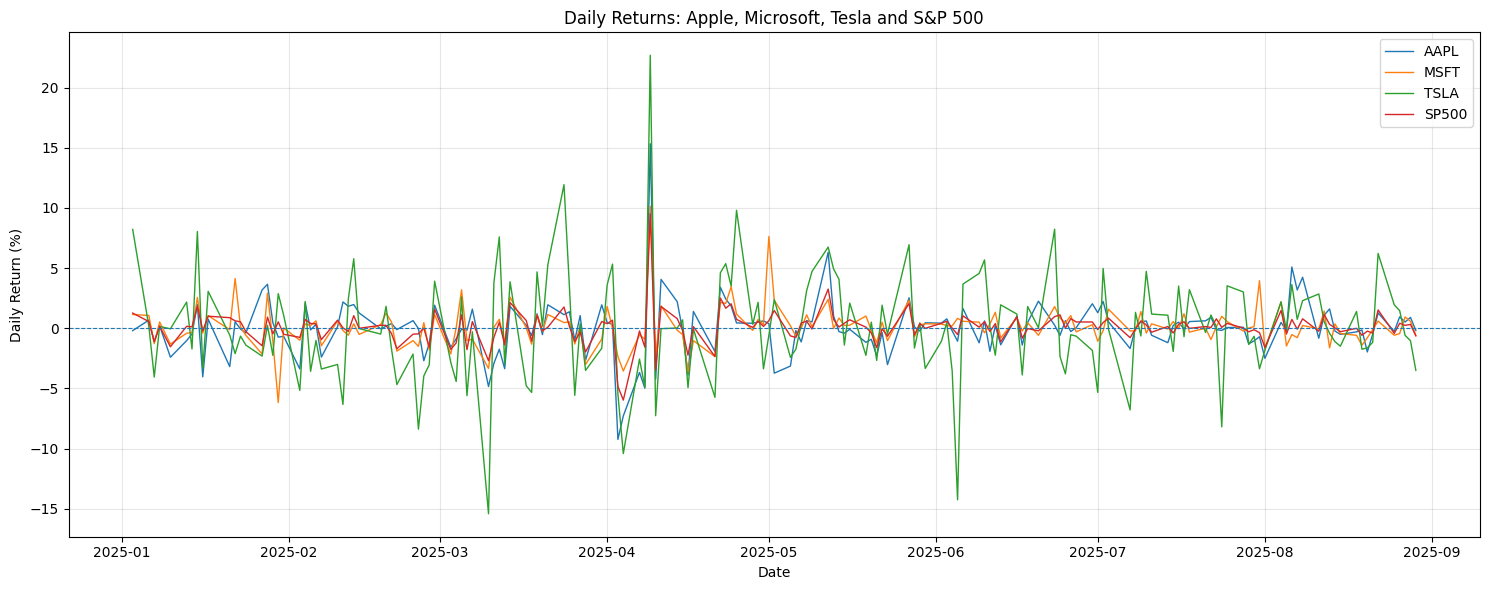

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

for column in daily_returns.columns:
    plt.plot(
        daily_returns.index,
        daily_returns[column],
        label=column,
        linewidth=1
    )

plt.axhline(y=0, linestyle="--", linewidth=0.8)

plt.title("Daily Returns: Apple, Microsoft, Tesla and S&P 500")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save closing prices
close_prices.to_csv(
    output_dir / "pilot_closing_prices.csv"
)

# Save daily returns
daily_returns.to_csv(
    output_dir / "pilot_daily_returns.csv"
)

print("Files saved successfully!")

print("\nSaved files:")
print(list(output_dir.glob("pilot_*.csv")))


Files saved successfully!

Saved files:
[WindowsPath('../data/processed/pilot_closing_prices.csv'), WindowsPath('../data/processed/pilot_daily_returns.csv')]
